# [Member 3] Integration and Post-Integration Cleaning

**Inputs** (pushed by Members 1 and 2):
- `data/clean/housing_clean.csv`: Affordable Housing Production by Building ([hg8x-zxpr](https://data.cityofnewyork.us/d/hg8x-zxpr)), one row per building per project.
- `data/clean/transport_clean.csv`: SIRTA serious-injury and fatal crashes ([xeqp-qz8h](https://data.cityofnewyork.us/d/xeqp-qz8h)), one row per crash.

**Output:** `data/clean/integrated_zip_year.csv`, one row per **ZIP code x year**, plus `data/clean/data_dictionary.md`.

**Steps in this notebook**
1. Load both clean files and record the starting row counts.
2. Choose the join key and granularity (ZIP x year) and justify it.
3. Restrict both files to the overlapping full years (2022-2025).
4. Aggregate each dataset to ZIP x year.
5. Merge (full outer join on a complete ZIP x year grid) and justify the join type.
6. Post-integration cleaning: new nulls, redundant/inconsistent columns, dtypes, rate outliers.
7. Validation plots and checks.
8. Save the integrated file and the data dictionary.

**Member 3 research questions**

Q5 (chart_05, box plot): Do ZIP codes that received the most new affordable housing face more serious and fatal crashes than ZIP codes that received none?
Q6 (chart_06, map): Is new affordable housing being completed in ZIP codes where serious crashes are rising, or where they are falling?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Works when run from the repo root or from notebooks/ (Colab: clone the repo first)
CLEAN_DIR = Path('data/clean') if Path('data/clean').exists() else Path('../data/clean')

housing = pd.read_csv(CLEAN_DIR / 'housing_clean.csv', dtype={'postcode': 'string'}, low_memory=False)
transport = pd.read_csv(CLEAN_DIR / 'transport_clean.csv', dtype={'zip_code': 'string'}, low_memory=False)

# Row-count log: every step appends here so Member 6 can plot before/after counts
row_log = [
    {'step': 'housing_clean.csv loaded', 'dataset': 'housing', 'rows': len(housing)},
    {'step': 'transport_clean.csv loaded', 'dataset': 'transport', 'rows': len(transport)},
]
print('Housing:', housing.shape, '| Transport:', transport.shape)

Housing: (7593, 51) | Transport: (13301, 33)


## 1. Choosing the join key and granularity

The two datasets share no ready-made key. A housing row is a **building**, a transport row is a **crash**, so
matching records one-to-one makes no sense. We checked the candidate bridges:

| Candidate | Housing | Transport | Verdict |
|---|---|---|---|
| Borough | yes (5 values) | yes | Too coarse: only 5 x 4 = 20 rows, nothing to correlate |
| Community board / NTA | yes | mostly empty in SIRTA | Too many nulls in transport |
| Lat/lon (spatial join) | yes | ~11% missing | Possible, but a crash "near a building" is not what our questions ask |
| **ZIP code** | 100% filled (`postcode`) | 89% filled after Member 2's nearest-centroid imputation | **Chosen** |
| **Year** | `completion_year`, `start_year` | `year` | **Chosen** |

**Why ZIP x year:** our questions compare neighbourhoods ("do ZIPs that build more affordable housing have more
serious crashes?") and how they change over time. A ZIP is small enough to separate neighbourhoods (~180 NYC ZIPs)
and large enough that most ZIP-years have several crashes, so counts are not all 0 or 1. Year matches how housing
completions are reported. Month would leave most ZIP-months empty for housing (only ~550 completions a year citywide).

In [ ]:
print('Housing rows without ZIP:', housing['postcode'].isna().sum())
print('Transport rows without ZIP:', transport['zip_code'].isna().sum(),
      f"({transport['zip_code'].isna().mean():.1%})")
print('\nHousing completion years:'); print(housing['completion_year'].value_counts().sort_index().to_string())
print('\nTransport years:'); print(transport['year'].value_counts().sort_index().to_string())
print('\nLatest crash date:', transport['crash_date'].max())

Housing rows without ZIP: 0
Transport rows without ZIP: 1494 (11.2%)

Housing completion years:
completion_year
2014.0     79
2015.0    163
2016.0    293
2017.0    681
2018.0    561
2019.0    746
2020.0    360
2021.0    494
2022.0    469
2023.0    639
2024.0    542
2025.0    591
2026.0    369

Transport years:
year
2022    2879
2023    3016
2024    3115
2025    2941
2026    1350

Latest crash date: 2026-06-30


## 2. Restrict to the overlapping full years: 2022-2025

- SIRTA (as downloaded by Member 2) starts on **2022-01-01**, so housing years before 2022 have no crash data to compare with.
- Both files stop at **2026-06-30**, so 2026 is only half a year. Keeping it would make 2026 look like a drop in
  both crashes and completions, which is an artefact. We **exclude 2026** and keep the 4 full years 2022-2025.
- **Housing time key:** we use `completion_year` (year the building was completed), because a completed building
  is when new residents actually arrive. Buildings with no completion date (still in progress) cannot be placed
  in a completion year. We keep them separately as `units_started` (by `start_year`) so that information is not lost.
- **Transport rows with no ZIP** (11%) cannot be placed in a ZIP and are dropped from the integration. This
  undercounts crashes slightly (mostly highway crashes with no address). We report the count below and
  list it as a limitation.

In [ ]:
YEARS = [2022, 2023, 2024, 2025]
NYC_ZIP_MIN, NYC_ZIP_MAX = 10001, 11697   # same valid NYC ZIP range Member 2 used

def valid_zip(series):
    """Return 5-digit ZIP strings, or <NA> if outside the NYC range."""
    z = series.astype('string').str.strip().str.extract(r'^(\d{5})')[0]
    num = pd.to_numeric(z, errors='coerce')
    return z.where(num.between(NYC_ZIP_MIN, NYC_ZIP_MAX))

housing['zip_code'] = valid_zip(housing['postcode'])
transport['zip_code'] = valid_zip(transport['zip_code'])

# Housing: completed buildings in 2022-2025
housing_done = housing[housing['completion_year'].isin(YEARS) & housing['zip_code'].notna()].copy()
# Housing: buildings started in 2022-2025 (includes in-progress projects)
housing_started = housing[housing['start_year'].isin(YEARS) & housing['zip_code'].notna()].copy()
# Transport: crashes in 2022-2025 with a ZIP
transport_yr = transport[transport['year'].isin(YEARS)]
row_log.append({'step': 'transport: 2022-2025 only', 'dataset': 'transport', 'rows': len(transport_yr)})
transport_zip = transport_yr[transport_yr['zip_code'].notna()].copy()

row_log += [
    {'step': 'housing: completed 2022-2025', 'dataset': 'housing', 'rows': len(housing_done)},
    {'step': 'transport: has ZIP', 'dataset': 'transport', 'rows': len(transport_zip)},
]
print('Housing buildings completed 2022-2025:', len(housing_done))
print('Housing buildings started 2022-2025:', len(housing_started))
print('Crashes 2022-2025:', len(transport_yr), '| with ZIP:', len(transport_zip),
      f'| dropped (no ZIP): {len(transport_yr) - len(transport_zip)} ({1 - len(transport_zip)/len(transport_yr):.1%})')

Housing buildings completed 2022-2025: 2241
Housing buildings started 2022-2025: 2555
Crashes 2022-2025: 11951 | with ZIP: 10563 | dropped (no ZIP): 1388 (11.6%)


## 3. Aggregate each dataset to ZIP x year

**Housing (completed buildings):** sum of units, broken down by affordability level and by construction type
(New Construction vs Preservation), plus counts of buildings and distinct projects. Missing unit sub-counts
are treated as 0 when summing: in this dataset a blank income-band column means the building has no units in
that band (the bands add up to `all_counted_units`).

**Transport:** number of crashes, injuries and fatalities. Every SIRTA record is already a serious-injury or
fatal crash, so `crash_count` is a count of serious crashes, not of all crashes.

In [ ]:
income_cols = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
housing_done[income_cols] = housing_done[income_cols].fillna(0)
housing_done['new_construction_units'] = np.where(
    housing_done['reporting_construction_type'] == 'New Construction', housing_done['total_units'], 0)
housing_done['preservation_units'] = np.where(
    housing_done['reporting_construction_type'] == 'Preservation', housing_done['total_units'], 0)
# "Deeply affordable" = extremely low + very low income (<= 50% AMI)
housing_done['deeply_affordable_units'] = (housing_done['extremely_low_income_units']
                                           + housing_done['very_low_income_units'])

housing_zy = (housing_done.rename(columns={'completion_year': 'year'})
              .groupby(['zip_code', 'year'], as_index=False)
              .agg(buildings_completed=('building_id', 'count'),
                   projects_completed=('project_id', 'nunique'),
                   total_units=('total_units', 'sum'),
                   new_construction_units=('new_construction_units', 'sum'),
                   preservation_units=('preservation_units', 'sum'),
                   deeply_affordable_units=('deeply_affordable_units', 'sum'),
                   low_income_units=('low_income_units', 'sum'),
                   housing_borough=('borough', lambda s: s.mode().iat[0]),
                   housing_lat=('latitude', 'mean'),
                   housing_lon=('longitude', 'mean')))

started_zy = (housing_started.rename(columns={'start_year': 'year'})
              .groupby(['zip_code', 'year'], as_index=False)
              .agg(units_started=('total_units', 'sum')))

transport_zy = (transport_zip.groupby(['zip_code', 'year'], as_index=False)
                .agg(crash_count=('open_data_crash_id', 'count'),
                     severe_injuries=('total_severe_injuries', 'sum'),
                     non_severe_injuries=('total_non_severe_injuries', 'sum'),
                     fatalities=('total_fatalities', 'sum'),
                     fatal_crashes=('total_fatalities', lambda s: int((s > 0).sum())),
                     transport_borough=('borough', lambda s: s.mode().iat[0] if s.notna().any() else pd.NA),
                     crash_lat=('latitude', 'mean'),
                     crash_lon=('longitude', 'mean')))

print('Housing ZIP-years:', housing_zy.shape, '| started ZIP-years:', started_zy.shape,
      '| Transport ZIP-years:', transport_zy.shape)
# Sanity check: aggregation must not lose or create units / crashes
assert housing_zy['total_units'].sum() == housing_done['total_units'].sum()
assert transport_zy['crash_count'].sum() == len(transport_zip)
housing_zy.head()

Housing ZIP-years: (391, 12) | started ZIP-years: (415, 3) | Transport ZIP-years: (714, 10)


,zip_code,year,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,deeply_affordable_units,low_income_units,housing_borough,housing_lat,housing_lon
0,10001,2023.0,2,2,1418.0,1418.0,0.0,94.0,238.0,MANHATTAN,40.750390,-73.999303
1,10001,2024.0,1,1,112.0,112.0,0.0,0.0,35.0,MANHATTAN,40.747629,-73.994265
2,10001,2025.0,1,1,277.0,277.0,0.0,31.0,25.0,MANHATTAN,40.753484,-74.004371
3,10002,2022.0,2,2,195.0,195.0,0.0,74.0,56.0,MANHATTAN,40.719043,-73.990204
4,10002,2023.0,1,1,59.0,59.0,0.0,0.0,6.0,MANHATTAN,40.717877,-73.982724


## 4. Merge: full outer join on a complete ZIP x year grid

**Join type options considered**

| Join | What happens | Problem |
|---|---|---|
| Inner | Keeps only ZIP-years with **both** a completion and a crash | Drops ~2/3 of crash ZIP-years. A ZIP with crashes but no new housing is real, useful information (the "0 units" group) |
| Left (housing) | Keeps housing ZIP-years only | Same problem, biased towards development areas |
| Left (transport) | Keeps crash ZIP-years only | Drops ZIP-years that built housing but had no serious crash |
| **Full outer + grid** | Every ZIP seen in either file x every year 2022-2025 | **Chosen.** No ZIP-year is lost, and each ZIP has a full time series |

**Why a grid:** an outer join alone only keeps ZIP-years where *something* happened. For line charts and year-on-year
comparisons, each ZIP needs a row for every year. We therefore build the grid (all ZIPs x 4 years) and left-join
both aggregates onto it.

**Why the missing values after the join can be set to 0:** both sources are complete city registers for this
window (every HPD-counted affordable building and every SIRTA crash). If a ZIP-year has no row, nothing was
recorded, so the count is a true 0, not unknown. This is different from a *rate*, which is undefined when the
denominator is 0 (see section 5).

In [ ]:
all_zips = sorted(set(housing_zy['zip_code']) | set(transport_zy['zip_code']) | set(started_zy['zip_code']))
grid = pd.MultiIndex.from_product([all_zips, YEARS], names=['zip_code', 'year']).to_frame(index=False)

integrated = (grid.merge(housing_zy, on=['zip_code', 'year'], how='left', indicator='_h')
                  .merge(transport_zy, on=['zip_code', 'year'], how='left', indicator='_t')
                  .merge(started_zy, on=['zip_code', 'year'], how='left'))

# Where did each row come from?
source = np.select([(integrated['_h'] == 'both') & (integrated['_t'] == 'both'),
                    integrated['_h'] == 'both', integrated['_t'] == 'both'],
                   ['both', 'housing only', 'transport only'], 'neither (grid fill)')
integrated['match_source'] = source
print(integrated['match_source'].value_counts().to_string())
print('\nRows after merge:', len(integrated), '=', len(all_zips), 'ZIPs x', len(YEARS), 'years')
row_log.append({'step': 'integrated ZIP x year grid', 'dataset': 'integrated', 'rows': len(integrated)})

match_source
both                   390
transport only         324
neither (grid fill)     33
housing only             1

Rows after merge: 748 = 187 ZIPs x 4 years


## 5. Post-integration cleaning

### 5.1 New missing values created by the join

In [ ]:
null_before = integrated.isna().mean().mul(100).round(1)
print('Null % right after the merge (non-zero only):')
print(null_before[null_before > 0].to_string())

Null % right after the merge (non-zero only):
buildings_completed        47.7
projects_completed         47.7
total_units                47.7
new_construction_units     47.7
preservation_units         47.7
deeply_affordable_units    47.7
low_income_units           47.7
housing_borough            47.7
housing_lat                47.7
housing_lon                47.7
crash_count                 4.5
severe_injuries             4.5
non_severe_injuries         4.5
fatalities                  4.5
fatal_crashes               4.5
transport_borough           4.5
crash_lat                   4.8
crash_lon                   4.8
units_started              44.5


In [ ]:
count_cols = ['buildings_completed', 'projects_completed', 'total_units', 'new_construction_units',
              'preservation_units', 'deeply_affordable_units', 'low_income_units', 'units_started',
              'crash_count', 'severe_injuries', 'non_severe_injuries', 'fatalities', 'fatal_crashes']
# Counts: missing = nothing recorded = 0 (justified in section 4)
integrated[count_cols] = integrated[count_cols].fillna(0)

### 5.2 Redundant and inconsistent columns

- **Two borough columns** (`housing_borough` in UPPER CASE, `transport_borough` in Title Case). We standardise
  to Title Case and merge them into one `borough`. A ZIP must have one borough so the borough filter works;
  we assign each ZIP the borough that appears most often for it across both files and all years. We count how
  many ZIPs had conflicting labels (ZIPs that straddle a borough line).
- **Two coordinate pairs** (mean housing location, mean crash location). Merged into one ZIP-level
  `latitude`/`longitude` (mean of all available points for the ZIP) for the map charts.
- `_h`, `_t` merge indicators are helper columns and are dropped after creating `match_source`.

In [ ]:
# Every building and crash row (2022-2025) "votes" for its ZIP's borough, in one common Title Case format
raw_points = pd.concat([
    housing_done[['zip_code', 'borough', 'latitude', 'longitude']],
    housing_started[['zip_code', 'borough', 'latitude', 'longitude']],
    transport_zip[['zip_code', 'borough', 'latitude', 'longitude']],
])
raw_points['borough'] = raw_points['borough'].astype('string').str.strip().str.title()
borough_votes = raw_points.dropna(subset=['borough'])
zip_borough = borough_votes.groupby('zip_code')['borough'].agg(lambda s: s.mode().iat[0])
conflicts = borough_votes.groupby('zip_code')['borough'].nunique()
print('ZIPs with conflicting borough labels:', int((conflicts > 1).sum()),
      list(conflicts[conflicts > 1].index))
integrated['borough'] = integrated['zip_code'].map(zip_borough)

# One coordinate per ZIP (stable across years so map points do not jump)
coords = raw_points[['zip_code', 'latitude', 'longitude']].set_axis(['zip_code', 'lat', 'lon'], axis=1)
zip_coords = coords.dropna().groupby('zip_code')[['lat', 'lon']].mean()
integrated['latitude'] = integrated['zip_code'].map(zip_coords['lat']).round(5)
integrated['longitude'] = integrated['zip_code'].map(zip_coords['lon']).round(5)

integrated = integrated.drop(columns=['_h', '_t', 'housing_borough', 'transport_borough',
                                      'housing_lat', 'housing_lon', 'crash_lat', 'crash_lon'])
print('ZIPs with no borough after merge:', integrated.loc[integrated['borough'].isna(), 'zip_code'].nunique())
print('ZIPs with no coordinates:', integrated.loc[integrated['latitude'].isna(), 'zip_code'].nunique())

ZIPs with conflicting borough labels: 15 ['10033', '10034', '10035', '10037', '10038', '10039', '10040', '10454', '10463', '11208', '11222', '11237', '11239', '11249', '11385']
ZIPs with no borough after merge: 0
ZIPs with no coordinates: 0


### 5.3 Category columns for the dashboard filters

The website needs one housing category and one transportation category per row:
- `housing_category`: the construction type with most units completed in that ZIP-year (`New Construction`,
  `Preservation`), or `No completions` when nothing was completed.
- `transport_category`: `Fatal crash recorded` if at least one fatal crash happened in that ZIP-year,
  `Serious injuries only` if there were crashes but none fatal, `No serious crashes` otherwise.

In [ ]:
integrated['housing_category'] = np.select(
    [integrated['total_units'] == 0, integrated['new_construction_units'] >= integrated['preservation_units']],
    ['No completions', 'New Construction'], 'Preservation')
integrated['transport_category'] = np.select(
    [integrated['fatal_crashes'] > 0, integrated['crash_count'] > 0],
    ['Fatal crash recorded', 'Serious injuries only'], 'No serious crashes')
print(integrated['housing_category'].value_counts().to_string()); print()
print(integrated['transport_category'].value_counts().to_string())

housing_category
No completions      357
New Construction    284
Preservation        107

transport_category
Fatal crash recorded     376
Serious injuries only    338
No serious crashes        34


### 5.4 Derived rates and rate outliers

- `crashes_per_100_units = crash_count / total_units * 100`. **Undefined (NaN) when `total_units` = 0**, because
  dividing by zero is meaningless; we do *not* fill it with 0, which would wrongly say "safe".
- `deeply_affordable_share = deeply_affordable_units / total_units` (NaN when no units).
- `injuries_per_crash = (severe + non-severe injuries) / crash_count` (NaN when no crashes).

Rates with a tiny denominator explode (1 crash / 1 unit = 100 per 100 units). We flag outliers with the IQR rule
(above Q3 + 1.5 x IQR) and also flag rows with a small unit base (< 20 units). We **keep** these rows, because
they are real, but charts that use the rate should filter on `flag_small_unit_base == False`.

In [ ]:
units = integrated['total_units'].replace(0, np.nan)
integrated['crashes_per_100_units'] = (integrated['crash_count'] / units * 100).round(2)
integrated['deeply_affordable_share'] = (integrated['deeply_affordable_units'] / units).round(3)
integrated['injuries_per_crash'] = ((integrated['severe_injuries'] + integrated['non_severe_injuries'])
                                    / integrated['crash_count'].replace(0, np.nan)).round(2)

def iqr_upper(series):
    """Upper IQR fence: Q3 + 1.5 * IQR, ignoring NaN."""
    q1, q3 = series.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

rate_fence = iqr_upper(integrated['crashes_per_100_units'])
integrated['flag_rate_outlier'] = integrated['crashes_per_100_units'] > rate_fence
integrated['flag_small_unit_base'] = integrated['total_units'].between(1, 19)
units_fence = iqr_upper(integrated.loc[integrated['total_units'] > 0, 'total_units'])
integrated['flag_units_outlier'] = integrated['total_units'] > units_fence

print(f'Rate fence: {rate_fence:.1f} crashes per 100 units ->', int(integrated['flag_rate_outlier'].sum()), 'outlier rows')
print('Small unit base rows:', int(integrated['flag_small_unit_base'].sum()))
print(f'Units fence: {units_fence:.0f} units ->', int(integrated['flag_units_outlier'].sum()), 'ZIP-years with very large completions (kept)')

Rate fence: 67.5 crashes per 100 units -> 43 outlier rows
Small unit base rows: 50
Units fence: 1081 units -> 21 ZIP-years with very large completions (kept)


### 5.5 Data types

After the merge, counts became floats (because NaN forced float), `year` must be an integer, `zip_code` must
stay a 5-character string (as a number, leading digits are fine in NYC but string avoids `10001.0`),
and categories should be category dtype.

In [ ]:
print('Before:'); print(integrated.dtypes.value_counts().to_string())
integrated[count_cols] = integrated[count_cols].round().astype('int64')
integrated['year'] = integrated['year'].astype('int64')
integrated['zip_code'] = integrated['zip_code'].astype('string')
for c in ['borough', 'housing_category', 'transport_category', 'match_source']:
    integrated[c] = integrated[c].astype('category')
print('\nAfter:'); print(integrated.dtypes.to_string())

Before:
float64    18
str         3
bool        3
object      1
int64       1
string      1

After:
zip_code                     string
year                          int64
buildings_completed           int64
projects_completed            int64
total_units                   int64
new_construction_units        int64
preservation_units            int64
deeply_affordable_units       int64
low_income_units              int64
crash_count                   int64
severe_injuries               int64
non_severe_injuries           int64
fatalities                    int64
fatal_crashes                 int64
units_started                 int64
match_source               category
borough                    category
latitude                    float64
longitude                   float64
housing_category           category
transport_category         category
crashes_per_100_units       float64
deeply_affordable_share     float64
injuries_per_crash          float64
flag_rate_outlier              bool


### 5.6 Final column order, duplicates and remaining nulls

In [ ]:
ordered = ['zip_code', 'borough', 'year', 'latitude', 'longitude',
           'buildings_completed', 'projects_completed', 'total_units', 'new_construction_units',
           'preservation_units', 'deeply_affordable_units', 'low_income_units', 'units_started',
           'housing_category',
           'crash_count', 'fatal_crashes', 'fatalities', 'severe_injuries', 'non_severe_injuries',
           'transport_category',
           'crashes_per_100_units', 'deeply_affordable_share', 'injuries_per_crash',
           'match_source', 'flag_rate_outlier', 'flag_small_unit_base', 'flag_units_outlier']
integrated = integrated[ordered].sort_values(['borough', 'zip_code', 'year']).reset_index(drop=True)

assert not integrated.duplicated(['zip_code', 'year']).any(), 'ZIP-year must be unique'
null_after = integrated.isna().mean().mul(100).round(1)
print('Remaining nulls (all expected: rates are undefined when the denominator is 0):')
print(null_after[null_after > 0].to_string())
print('\nFinal shape:', integrated.shape)
integrated.head()

Remaining nulls (all expected: rates are undefined when the denominator is 0):
crashes_per_100_units      47.7
deeply_affordable_share    47.7
injuries_per_crash          4.5

Final shape: (748, 27)


,zip_code,borough,year,latitude,longitude,buildings_completed,projects_completed,total_units,new_construction_units,preservation_units,...,severe_injuries,non_severe_injuries,transport_category,crashes_per_100_units,deeply_affordable_share,injuries_per_crash,match_source,flag_rate_outlier,flag_small_unit_base,flag_units_outlier
0,10451,Bronx,2022,40.82069,-73.92309,3,3,544,544,0,...,28,4,Fatal crash recorded,5.15,0.257,1.14,both,False,False,False
1,10451,Bronx,2023,40.82069,-73.92309,12,6,2937,1063,1874,...,22,7,Serious injuries only,0.68,0.278,1.45,both,False,False,True
2,10451,Bronx,2024,40.82069,-73.92309,11,11,1683,1643,40,...,22,6,Fatal crash recorded,1.49,0.030,1.12,both,False,False,True
3,10451,Bronx,2025,40.82069,-73.92309,6,6,279,210,69,...,25,9,Fatal crash recorded,9.32,0.176,1.31,both,False,False,False
4,10452,Bronx,2022,40.83879,-73.92192,6,6,590,530,60,...,51,13,Fatal crash recorded,8.14,0.368,1.33,both,False,False,False


## 6. Validation

Checks that integration did not lose or invent data, plus plots for Member 6.

In [ ]:
checks = pd.DataFrame({
    'metric': ['Units completed 2022-2025', 'Crashes 2022-2025 with ZIP'],
    'before integration': [int(housing_done['total_units'].sum()), len(transport_zip)],
    'after integration': [int(integrated['total_units'].sum()), int(integrated['crash_count'].sum())],
})
checks['match'] = checks['before integration'] == checks['after integration']
print(checks.to_string(index=False))
assert checks['match'].all()

                    metric  before integration  after integration  match
 Units completed 2022-2025              142480             142480   True
Crashes 2022-2025 with ZIP               10563              10563   True


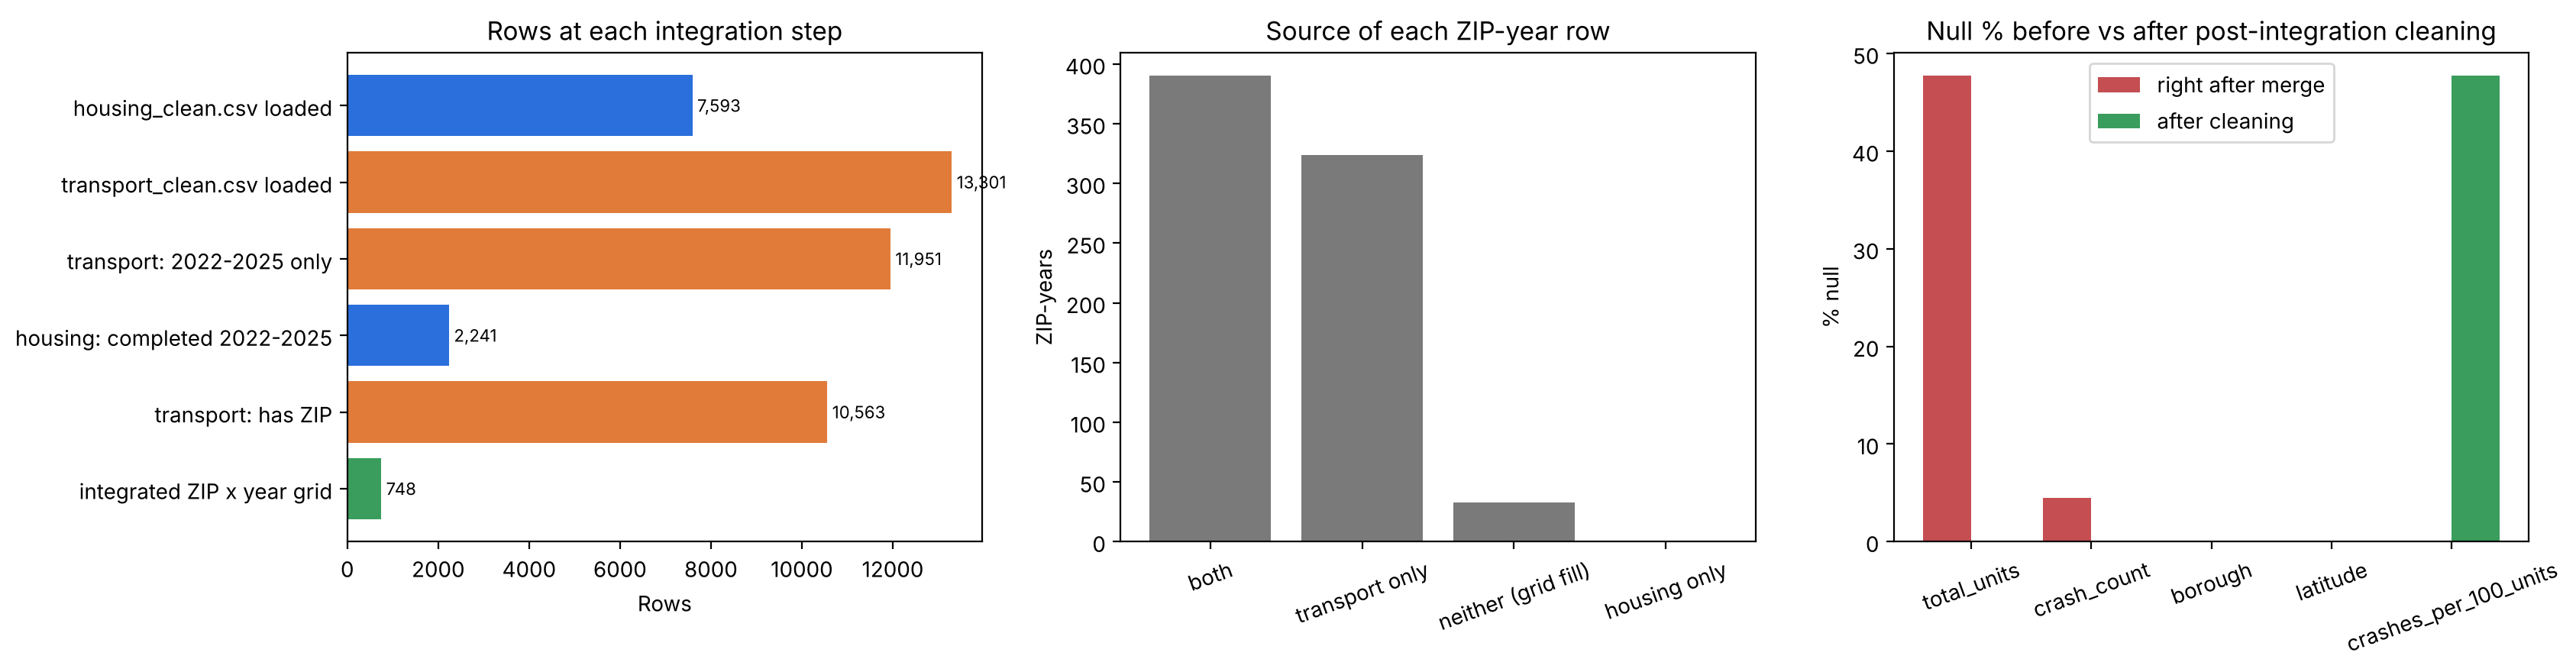

In [ ]:
row_log_df = pd.DataFrame(row_log)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) Rows at each step
colors = row_log_df['dataset'].map({'housing': '#2a6fdb', 'transport': '#e07b39', 'integrated': '#3a9d5d'})
axes[0].barh(row_log_df['step'], row_log_df['rows'], color=colors)
axes[0].invert_yaxis(); axes[0].set_xlabel('Rows'); axes[0].set_title('Rows at each integration step')
for i, v in enumerate(row_log_df['rows']):
    axes[0].text(v, i, f' {v:,}', va='center', fontsize=8)

# (b) Where the merged rows came from
src = integrated['match_source'].value_counts()
axes[1].bar(src.index.astype(str), src.values, color='#7a7a7a')
axes[1].set_title('Source of each ZIP-year row'); axes[1].set_ylabel('ZIP-years')
axes[1].tick_params(axis='x', rotation=20)

# (c) Null % before vs after post-integration cleaning
cols_show = ['total_units', 'crash_count', 'borough', 'latitude', 'crashes_per_100_units']
# borough/latitude/rate only exist after 5.2 and 5.4, so they have no "right after merge" value
nb = [null_before['total_units'], null_before['crash_count'], 0, 0, 0]
na = [null_after.get(c, 0) for c in cols_show]
x = np.arange(len(cols_show))
axes[2].bar(x - 0.2, np.nan_to_num(nb), 0.4, label='right after merge', color='#c44e52')
axes[2].bar(x + 0.2, na, 0.4, label='after cleaning', color='#3a9d5d')
axes[2].set_xticks(x, cols_show, rotation=20); axes[2].set_ylabel('% null')
axes[2].set_title('Null % before vs after post-integration cleaning'); axes[2].legend()
plt.tight_layout(); plt.show()

Note on chart (c): `borough`, `latitude` and the rate did not exist as single columns right after the merge
(they were created in 5.2 and 5.4), so their "before" bar is 0. The rate's remaining nulls are intentional:
ZIP-years with no completed units.

In [ ]:
# Quick look at the cross-domain relationship (Members 1 and others will build the real charts)
city = integrated.groupby('year')[['total_units', 'crash_count']].sum()
print(city)
active = integrated[integrated['total_units'] > 0]
print('\nSpearman correlation, units vs crashes (ZIP-years with completions):',
      round(active['total_units'].corr(active['crash_count'], method='spearman'), 3))

      total_units  crash_count
year                          
2022        28757         2482
2023        41279         2655
2024        33460         2680
2025        38984         2746



Spearman correlation, units vs crashes (ZIP-years with completions): 0.303


## 7. Save

In [ ]:
out_csv = CLEAN_DIR / 'integrated_zip_year.csv'
integrated.to_csv(out_csv, index=False)
row_log_df.to_csv(CLEAN_DIR / 'integration_row_log.csv', index=False)
print('Saved', out_csv, integrated.shape)

Saved ../data/clean/integrated_zip_year.csv (748, 27)


## Limitations of the integration

- **Crashes without a ZIP are dropped** (about 11% of 2022-2025 crashes, mostly on highways). Crash counts per ZIP are slightly low.
- **ZIP codes are postal routes, not neighbourhoods**: a few ZIPs straddle a borough line, and each ZIP gets one borough label (majority vote).
- **Affordable housing only**: the housing data covers HPD-counted affordable buildings, not all new construction, so a ZIP with 0 units may still have market-rate development.
- **Serious crashes only**: SIRTA records serious-injury and fatal crashes, not all crashes or traffic volume, so `crash_count` measures severe risk, not travel.
- **No population or traffic denominator**: busier ZIPs have more crashes simply because more people travel there. Comparisons between ZIPs are associations, not causes.
- **2026 excluded** because both files stop on 2026-06-30.
- The same building can appear in two projects (123 rows); its units are counted once per project, as HPD reports them.